In [78]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine
import pandas as pd
import matplotlib.pyplot as plt

# Carrega variaveis do arquivo .env
load_dotenv()

In [79]:
DATABASE_URL = os.getenv("DATABASE_URL")
engine = create_engine(DATABASE_URL)

In [80]:
sql = """
    SELECT 
        p.product_category_name,
        SUM(oi.price) AS receita_total,
        COUNT(*) AS qtd_items,
        AVG(oi.price) AS preco_medio,
        SUM(oi.price) / COUNT(*) AS receita_media_por_item
    FROM 
        order_items oi
    JOIN products p
    ON oi.product_id = p.product_id
    GROUP BY p.product_category_name
    ORDER BY receita_total DESC
    LIMIT 10;
    """
df = pd.read_sql_query(sql, engine)
df.head()

,product_category_name,receita_total,qtd_items,preco_medio,receita_media_por_item
0,beleza_saude,1258681.34,9670,130.163531,130.163531
1,relogios_presentes,1205005.68,5991,201.135984,201.135984
2,cama_mesa_banho,1036988.68,11115,93.296327,93.296327
3,esporte_lazer,988048.97,8641,114.344285,114.344285
4,informatica_acessorios,911954.32,7827,116.513903,116.513903


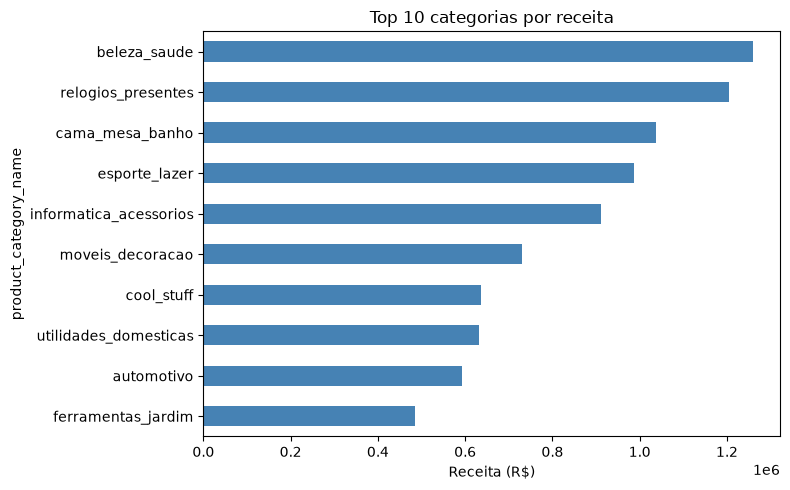

In [81]:
df.plot.barh(
    x='product_category_name',
    y='receita_total',
    legend=False,
    figsize=(8,5),
    color='steelblue')
plt.xlabel('Receita (R$)')
plt.title('Top 10 categorias por receita')
plt.gca().invert_yaxis()   # maior no topo
plt.tight_layout()
plt.show()

Interpretação

- Beleza & Saúde tem a maior receita e um preço médio de ~R$ 130, indicando bom volume 
e valor.

- Relógios & Presentes tem receita alta, porém menos itens e preço médio ~R$ 200 → produto premium.

In [82]:
sql = """
SELECT 
    DATE_TRUNC('month', o.order_purchase_timestamp) AS mes,
    SUM(oi.price) AS receita_mensal
FROM orders o 
JOIN order_items oi ON oi.order_id = o.order_id
GROUP BY mes
ORDER BY mes;
"""

df = pd.read_sql_query(sql, engine)
df.head()

,mes,receita_mensal
0,2016-09-01,267.36
1,2016-10-01,49507.66
2,2016-12-01,10.90
3,2017-01-01,120312.87
4,2017-02-01,247303.02


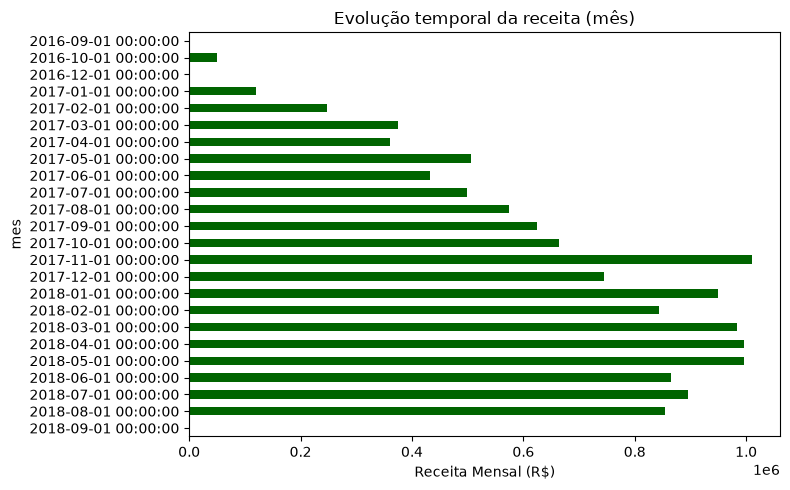

In [83]:
df.plot.barh(
    x='mes',
    y='receita_mensal',
    legend=False,
    figsize = (8,5),
    color='darkgreen'
)
plt.xlabel('Receita Mensal (R$)')
plt.title('Evolução temporal da receita (mês)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Interpretação 

- O mês 11/2017 juntamente a os meses 04/2018 e 05/2018 possuem as maiores receitas mensais

- O mês 09/2016 (primeiro registo) junto ao mês 12/2016 e o mês 9/2018 (ultimo registro) possuem a menor receita mensal

In [ ]:
sql = """
WITH 
recencia AS (
    SELECT
        c.customer_id,
        MAX(o.order_purchase_timestamp) AS ultima_compra,
        CURRENT_DATE - DATE(MAX(o.order_purchase_timestamp)) AS recencia_dias
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY c.customer_id
),
frequencia AS (
    SELECT
        c.customer_id,
        COUNT(o.order_id) AS qtd_pedidos
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    GROUP BY c.customer_id
),
monetario AS (
    SELECT
        c.customer_id,
        SUM(oi.price) AS valor_total
    FROM customers c
    JOIN orders o ON c.customer_id = o.customer_id
    JOIN order_items oi ON o.order_id = oi.order_id
    GROUP BY c.customer_id
),
rfm_quartil AS (
SELECT 
    r.customer_id,
    r.recencia_dias,
    f.qtd_pedidos,
    m.valor_total,
    NTILE(4) OVER (ORDER BY r.recencia_dias ASC) AS recencia_quartil,
    NTILE(4) OVER (ORDER BY f.qtd_pedidos DESC) AS frequencia_quartil,
    NTILE(4) OVER (ORDER BY m.valor_total DESC) AS monetario_quartil
FROM recencia r
JOIN frequencia f ON r.customer_id = f.customer_id
JOIN monetario m ON r.customer_id = m.customer_id
)
SELECT *,
    CASE
        WHEN recencia_quartil = 1
        AND  frequencia_quartil = 4
        AND  monetario_quartil = 4
        THEN 'Best' 
        ELSE 'Other'
    END AS segmento
FROM rfm_quartil 
ORDER BY segmento, valor_total DESC;
"""

df_rfm = pd.read_sql_query(sql, engine)
df_rfm.head()

,customer_id,recencia_dias,qtd_pedidos,valor_total,recencia_quartil,frequencia_quartil,monetario_quartil,segmento
0,1617b1357756262bfa56ab541c47bc16,3328,1,13440.0,3,1,1,Other
1,ec5b2ba62e574342386871631fafd3fc,3039,1,7160.0,1,1,1,Other
2,c6e2731c5b391845f6800c97401a43a9,3557,1,6735.0,4,1,1,Other
3,f48d464a0baaea338cb25f816991ab1f,3029,1,6729.0,1,1,1,Other
4,3fd6777bbce08a352fddd04e4a7cc8f6,3456,1,6499.0,4,1,1,Other


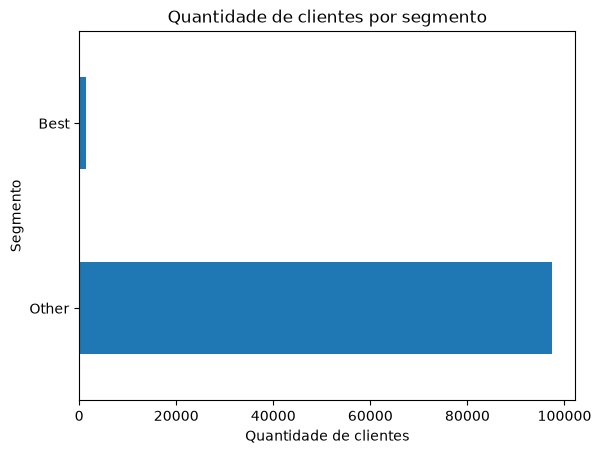

In [88]:
df_rfm['segmento'].value_counts().plot.barh()

plt.title('Quantidade de clientes por segmento')
plt.xlabel('Quantidade de clientes')
plt.ylabel('Segmento')
plt.show()